<a href="https://colab.research.google.com/github/hasby-umutoniwabo/Formative-2-HMM_Activity_Recognition/blob/main/notebook/HMM_Activity_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Setup

In [2]:
import os
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility: the HMM is trained with random initialisation, so without a fixed seed the numbers change on every run and the report can't be checked
RNG = np.random.default_rng(42)

#  Recording configuration (as set in Sensor Logger)
FS_NOMINAL = 50.0
TRIM_S     = 1.5
FILE_S     = 7.0
WINDOW_S   = 4.0
OVERLAP    = 0.5

ACTIVITIES = ["still", "standing", "walking", "jumping"]
N_STATES   = len(ACTIVITIES)

SAMPLES_PER_FILE   = int(FILE_S * FS_NOMINAL)      # 400
SAMPLES_PER_WINDOW = int(WINDOW_S * FS_NOMINAL)    # 200
WINDOW_STEP        = int(SAMPLES_PER_WINDOW * (1 - OVERLAP))   # 100

print(f"Sampling rate      : {FS_NOMINAL:.0f} Hz")
print(f"File length        : {FILE_S:.0f} s  = {SAMPLES_PER_FILE} samples")
print(f"Analysis window    : {WINDOW_S:.0f} s  = {SAMPLES_PER_WINDOW} samples")
print(f"Window step        : {WINDOW_STEP} samples ({OVERLAP:.0%} overlap)")
print(f"Frequency resolution: {FS_NOMINAL/SAMPLES_PER_WINDOW:.3f} Hz")

Sampling rate      : 50 Hz
File length        : 7 s  = 350 samples
Analysis window    : 4 s  = 200 samples
Window step        : 100 samples (50% overlap)
Frequency resolution: 0.250 Hz


Unpack the Data

In [3]:
import shutil

DRIVE_ZIP = "/content/drive/MyDrive/STUDY/HMM_Project/Data.zip"
RAW_DIR   = "/content/data/raw"

assert os.path.exists(DRIVE_ZIP), f"Not found: {DRIVE_ZIP}"

shutil.rmtree("/content/data", ignore_errors=True)
os.makedirs(RAW_DIR, exist_ok=True)

with zipfile.ZipFile(DRIVE_ZIP) as z:
    z.extractall("/content/data/_outer")

for path in sorted(glob.glob("/content/data/_outer/**/*.zip", recursive=True)):
    session_name = os.path.basename(path)[:-4]        # drop the .zip
    with zipfile.ZipFile(path) as z:
        z.extractall(os.path.join(RAW_DIR, session_name))

shutil.rmtree("/content/data/_outer")

sessions = sorted(os.listdir(RAW_DIR))
n_test = sum("test" in s for s in sessions)

print(f"Unpacked {len(sessions)} recordings ({n_test} test, {len(sessions)-n_test} training)\n")
for s in sessions:
    print("   ", s)

Unpacked 26 recordings (4 test, 22 training)

    jumping-2-23-2026-10-25_19-11-19
    jumping-3-25-2026-10-25_19-12-04
    jumping-4-24-2026-10-25_19-12-47
    jumping-5-24-2026-10-25_19-16-37
    jumping-test-2026-10-26_10-36-56
    jumping_1-2026-10-25_18-33-39
    jumping_1-29-2026-10-25_19-10-15
    standing-1-44-2026-10-25_19-04-58
    standing-2-45-2026-10-25_19-06-00
    standing-3-44-2026-10-25_19-07-06
    standing-4-44-2026-10-25_19-08-06
    standing-test-2026-10-26_10-37-41
    standing_1-2026-10-25_18-34-37
    still-1-44-2026-10-25_19-14-23
    still-2-44-2026-10-25_19-15-22
    still-3-44-2026-10-25_19-17-56
    still-4-44-2026-10-25_19-19-11
    still-test-2026-10-26_10-40-46
    still_1-2026-10-25_18-35-56
    walking-2026-10-25_18-25-56
    walking-2026-10-25_18-25-56 (1)
    walking-test-2026-10-26_10-29-02
    walking_1-2026-10-25_18-25-56
    walking_3_44-2026-10-25_18-59-37
    walking_4_44-2026-10-25_19-01-01
    walking_final_47-2026-10-25_19-02-11


Loader and quality control audit

In [4]:
def label_of(folder):
    """Activity label is the first token of the folder name."""
    return folder.split("-")[0].split("_")[0].lower()


def is_test(folder):
    """Sessions recorded on the second day are marked 'test' in their name."""
    return "test" in folder.lower()


def load_session(folder):
    """Merge the three sensor files of one recording into a single DataFrame.

    Sensor Logger writes the axis columns in the order z,y,x -- we reorder them once
    here so nothing downstream has to remember that.
    """
    path = os.path.join(RAW_DIR, folder)
    acc = pd.read_csv(f"{path}/Accelerometer.csv")[["time", "seconds_elapsed", "x", "y", "z"]]
    gyr = pd.read_csv(f"{path}/Gyroscope.csv")[["time", "x", "y", "z"]]
    grv = pd.read_csv(f"{path}/Gravity.csv")[["time", "x", "y", "z"]]

    aligned = acc["time"].equals(gyr["time"]) and acc["time"].equals(grv["time"])

    df = acc.rename(columns={"x": "acc_x", "y": "acc_y", "z": "acc_z"})
    df[["gyr_x", "gyr_y", "gyr_z"]]    = gyr[["x", "y", "z"]].values
    df[["grav_x", "grav_y", "grav_z"]] = grv[["x", "y", "z"]].values
    return df, aligned

EXCLUDE = {
    "jumping_1-2026-10-25_18-33-39":   "pre-protocol grip, gravity on z (-9.49)",
    "standing_1-2026-10-25_18-34-37":  "pre-protocol grip, gravity on z (-9.18)",
    "still_1-2026-10-25_18-35-56":     "pre-protocol session, 10 s only",
    "walking-2026-10-25_18-25-56":     "tilted grip, gravity split x/z",
    "walking-2026-10-25_18-25-56 (1)": "duplicate export of 18-25-56",
    "walking_1-2026-10-25_18-25-56":   "duplicate export of 18-25-56",
}

rows = []
for folder in sessions:
    df, aligned = load_session(folder)
    t  = df["seconds_elapsed"].values
    dt = np.diff(t)

    rows.append(dict(
        session   = folder,
        activity  = label_of(folder),
        split     = "test" if is_test(folder) else "train",
        duration  = t[-1] - t[0],
        samples   = len(df),
        fs_meas   = 1.0 / dt.mean(),          # measured rate, not the configured one
        jitter_ms = dt.std() * 1000,          # spread of the sample interval
        aligned   = aligned,
        status    = EXCLUDE.get(folder, "included"),
    ))

manifest = pd.DataFrame(rows)

pd.set_option("display.width", 200)
print(manifest.to_string(index=False, float_format=lambda v: f"{v:8.3f}"))

print(f"\nMeasured sampling rate : {manifest.fs_meas.mean():.3f} Hz "
      f"(range {manifest.fs_meas.min():.3f} - {manifest.fs_meas.max():.3f})")
print(f"Worst timing jitter    : {manifest.jitter_ms.max():.4f} ms "
      f"({manifest.jitter_ms.max() / (1000/FS_NOMINAL) * 100:.3f}% of the sample interval)")
print(f"Sensors time-aligned   : {manifest.aligned.all()} (all {len(manifest)} sessions)")

                             session activity split  duration  samples  fs_meas  jitter_ms  aligned                                  status
    jumping-2-23-2026-10-25_19-11-19  jumping train    23.350     1173   50.193      0.001     True                                included
    jumping-3-25-2026-10-25_19-12-04  jumping train    25.322     1272   50.193      0.000     True                                included
    jumping-4-24-2026-10-25_19-12-47  jumping train    24.784     1245   50.193      0.000     True                                included
    jumping-5-24-2026-10-25_19-16-37  jumping train    24.465     1229   50.193      0.000     True                                included
    jumping-test-2026-10-26_10-36-56  jumping  test    26.253     1319   50.204      0.000     True                                included
       jumping_1-2026-10-25_18-33-39  jumping train     9.145      460   50.193      0.001     True pre-protocol grip, gravity on z (-9.49)
    jumping_1-29-202

Slice into labelled files

In [5]:
TRAIN_DIR = "/content/data/train"
TEST_DIR  = "/content/data/test"
for d in (TRAIN_DIR, TEST_DIR):
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d)


def slice_session(df, label, session_id, out_dir):
    t = df["seconds_elapsed"].values

    # Drop the first and last 1.5 s: that is reaching for the button, not activity.
    keep = (t >= t[0] + TRIM_S) & (t <= t[-1] - TRIM_S)
    body = df.loc[keep].reset_index(drop=True)

    MIN_SAMPLES = int(5.0 * FS_NOMINAL)

    n, i = 0, 0
    while i + MIN_SAMPLES <= len(body):
        chunk = body.iloc[i : i + SAMPLES_PER_FILE].copy()
        chunk["label"] = label
        n += 1
        chunk.to_csv(f"{out_dir}/{label}_{session_id}_w{n:02d}.csv", index=False)
        i += SAMPLES_PER_FILE
    return n


counter = {}
for _, row in manifest.iterrows():
    if row.status != "included":
        continue

    df, _ = load_session(row.session)
    key   = (row.activity, row.split)
    counter[key] = counter.get(key, 0) + 1          # unique id per activity per split
    sid   = f"{'t' if row.split == 'test' else 's'}{counter[key]}"

    slice_session(df, row.activity, sid, TEST_DIR if row.split == "test" else TRAIN_DIR)


def summarise(d, name):
    files = sorted(glob.glob(f"{d}/*.csv"))
    tab = pd.Series([os.path.basename(f).split("_")[0] for f in files]).value_counts()
    secs = {a: sum(len(pd.read_csv(f)) for f in files
                   if os.path.basename(f).startswith(a)) / FS_NOMINAL for a in ACTIVITIES}
    print(f"{name}: {len(files)} files")
    for act in ACTIVITIES:
        flag = "" if secs[act] >= 90 or name == "TEST" else "   <-- under 90 s"
        print(f"   {act:9s} {tab.get(act,0):3d} files = {secs[act]:5.0f} s{flag}")

summarise(TRAIN_DIR, "TRAIN")
print()
summarise(TEST_DIR, "TEST")

TRAIN: 82 files
   still      24 files =   164 s
   standing   24 files =   166 s
   walking    18 files =   124 s
   jumping    16 files =   110 s

TEST: 12 files
   still       3 files =    21 s
   standing    3 files =    21 s
   walking     3 files =    21 s
   jumping     3 files =    21 s


Raw signal plots

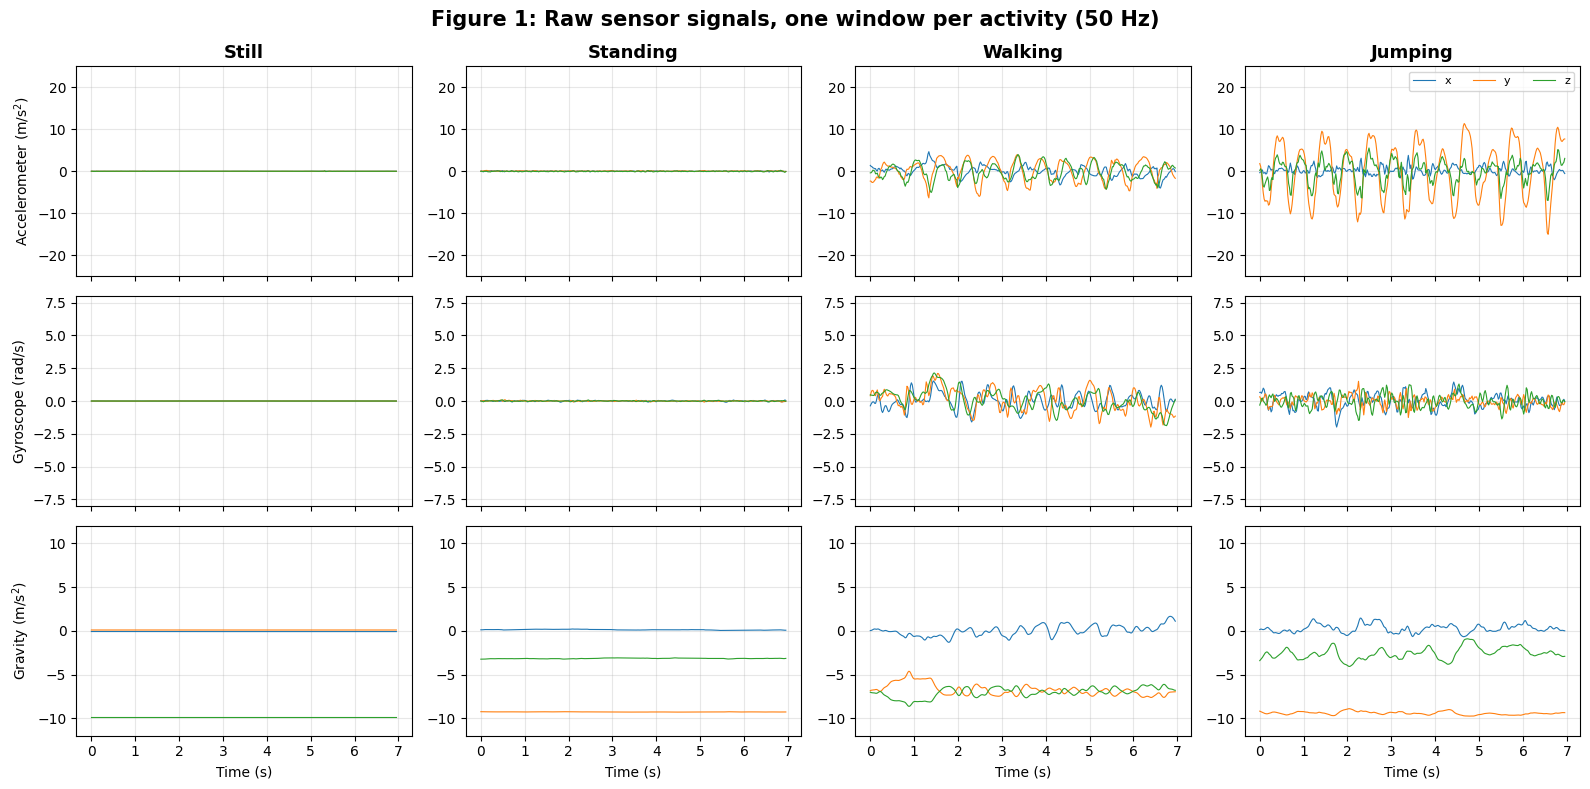

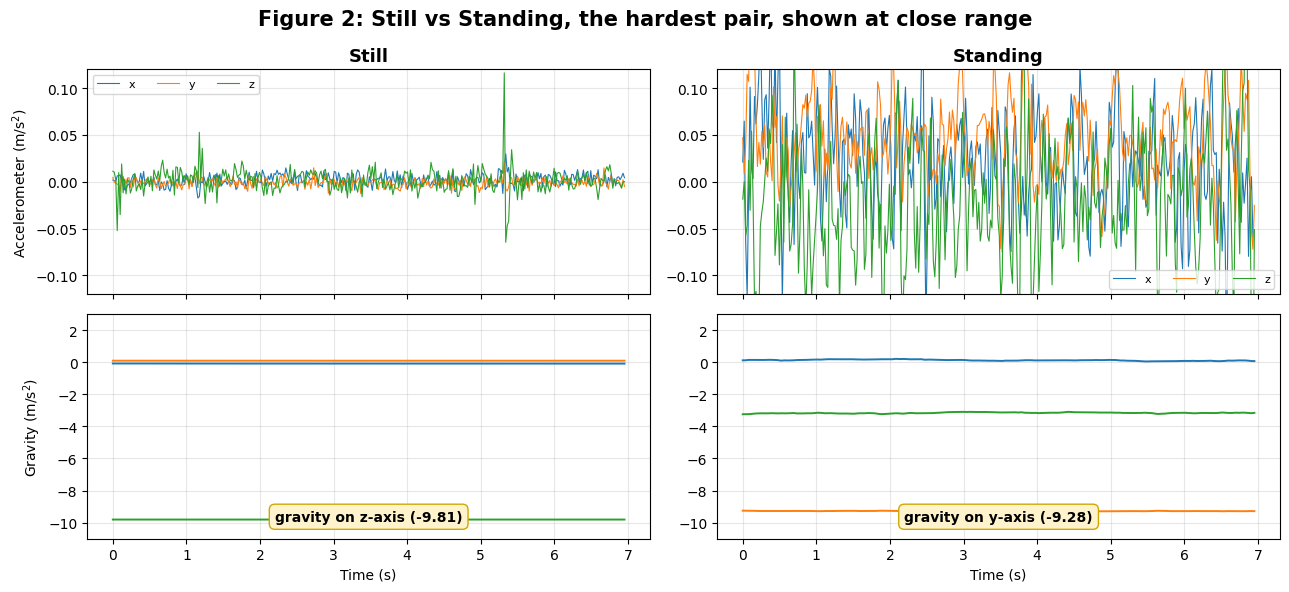

still     mean|acc|=0.0119  mean|gyro|=0.0027
standing  mean|acc|=0.1012  mean|gyro|=0.0408


In [6]:
fig, axes = plt.subplots(3, 4, figsize=(16, 8), sharex=True)
SENSORS = [("acc", "Accelerometer (m/s$^2$)", 25),
           ("gyr", "Gyroscope (rad/s)", 8),
           ("grav", "Gravity (m/s$^2$)", 12)]

for col, act in enumerate(ACTIVITIES):
    df = pd.read_csv(f"{TRAIN_DIR}/{act}_s1_w01.csv")
    t  = df.seconds_elapsed - df.seconds_elapsed.iloc[0]

    for row, (pre, ylab, lim) in enumerate(SENSORS):
        ax = axes[row, col]
        for ax_name, c in zip("xyz", ["#1f77b4", "#ff7f0e", "#2ca02c"]):
            ax.plot(t, df[f"{pre}_{ax_name}"], lw=0.8, color=c, label=ax_name)
        ax.set_ylim(-lim, lim); ax.grid(alpha=.3)
        if row == 0: ax.set_title(act.capitalize(), fontsize=13, weight="bold")
        if col == 0: ax.set_ylabel(ylab)
        if row == 2: ax.set_xlabel("Time (s)")
        if row == 0 and col == 3: ax.legend(fontsize=8, ncol=3, loc="upper right")

fig.suptitle("Figure 1: Raw sensor signals, one window per activity (50 Hz)",
             fontsize=15, weight="bold")
fig.tight_layout(); plt.show()


fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)

for col, act in enumerate(["still", "standing"]):
    df = pd.read_csv(f"{TRAIN_DIR}/{act}_s1_w01.csv")
    t  = df.seconds_elapsed - df.seconds_elapsed.iloc[0]

    ax = axes[0, col]
    for a, c in zip("xyz", ["#1f77b4", "#ff7f0e", "#2ca02c"]):
        ax.plot(t, df[f"acc_{a}"], lw=.8, color=c, label=a)
    ax.set_ylim(-.12, .12); ax.grid(alpha=.3); ax.legend(fontsize=8, ncol=3)
    ax.set_title(act.capitalize(), fontsize=13, weight="bold")
    if col == 0: ax.set_ylabel("Accelerometer (m/s$^2$)")

    ax = axes[1, col]
    for a, c in zip("xyz", ["#1f77b4", "#ff7f0e", "#2ca02c"]):
        ax.plot(t, df[f"grav_{a}"], lw=1.4, color=c)
    ax.set_ylim(-11, 3); ax.grid(alpha=.3); ax.set_xlabel("Time (s)")
    if col == 0: ax.set_ylabel("Gravity (m/s$^2$)")

    g = df[["grav_x", "grav_y", "grav_z"]].mean()
    dom_axis = g.abs().idxmax()
    ax.annotate(f"gravity on {dom_axis[-1]}-axis ({g[dom_axis]:.2f})",
                xy=(.5, .08), xycoords="axes fraction", ha="center",
                fontsize=10, weight="bold",
                bbox=dict(boxstyle="round,pad=0.4", fc="#fff3cd", ec="#d0a800"))

fig.suptitle("Figure 2: Still vs Standing, the hardest pair, shown at close range",
             fontsize=15, weight="bold")
fig.tight_layout(); plt.show()

for act in ["still", "standing"]:
    d = pd.read_csv(f"{TRAIN_DIR}/{act}_s1_w01.csv")
    print(f"{act:9s} mean|acc|={np.linalg.norm(d[['acc_x','acc_y','acc_z']],axis=1).mean():.4f}"
          f"  mean|gyro|={np.linalg.norm(d[['gyr_x','gyr_y','gyr_z']],axis=1).mean():.4f}")

Feature extraction

In [7]:
def extract_features(win):
    A = win[["acc_x", "acc_y", "acc_z"]].values
    G = win[["gyr_x", "gyr_y", "gyr_z"]].values
    V = win[["grav_x", "grav_y", "grav_z"]].values

    a_mag = np.linalg.norm(A, axis=1)
    g_mag = np.linalg.norm(G, axis=1)

    # Signed vertical acceleration. |A| would report double the true cadence.
    unit_g = V / np.linalg.norm(V, axis=1, keepdims=True)
    vert   = (A * unit_g).sum(axis=1)

    # Time domain
    f_var_v = vert.var()
    f_rms_a = np.sqrt((a_mag ** 2).mean())
    f_sma   = np.abs(A).sum() / len(A)
    f_gyro  = g_mag.mean()
    f_range = vert.max() - vert.min()
    f_corr  = np.corrcoef(A[:, 0], A[:, 1])[0, 1]
    if not np.isfinite(f_corr):
        f_corr = 0.0

    # Orientation: upright loads y, flat on a table loads z
    f_gx, f_gy, f_gz = V.mean(axis=0)

    # Frequency domain
    sig  = vert - vert.mean()
    spec = np.abs(np.fft.rfft(sig * np.hanning(len(sig))))
    freq = np.fft.rfftfreq(len(sig), 1 / FS_NOMINAL)

    band = (freq >= 0.3) & (freq <= 12)
    f_domfreq = freq[band][np.argmax(spec[band])]
    f_energy  = (spec ** 2).sum() / len(spec)

    # Rhythmic motion peaks sharply (low entropy), noise is flat (high).
    p = spec[band] ** 2
    p = p / (p.sum() + 1e-12)
    f_entropy = -(p * np.log(p + 1e-12)).sum() / np.log(len(p))

    return np.array([f_var_v, f_rms_a, f_sma, f_gyro, f_range, f_corr,
                     f_gx, f_gy, f_gz,
                     f_domfreq, f_energy, f_entropy])


FEATURE_NAMES = ["var_vert", "rms_acc", "sma", "gyro_mean", "range_vert", "corr_xy",
                 "grav_x", "grav_y", "grav_z",
                 "dom_freq", "spec_energy", "spec_entropy"]
N_FEATURES = len(FEATURE_NAMES)


def featurise_file(path):
    df = pd.read_csv(path)
    return np.array([extract_features(df.iloc[i:i + SAMPLES_PER_WINDOW])
                     for i in range(0, len(df) - SAMPLES_PER_WINDOW + 1, WINDOW_STEP)])


def build_split(directory):
    # One file = one observation sequence.
    seqs, labels, names = [], [], []
    for path in sorted(glob.glob(f"{directory}/*.csv")):
        X = featurise_file(path)
        if len(X) == 0:
            continue
        act = os.path.basename(path).split("_")[0]
        seqs.append(X)
        labels.append(np.full(len(X), ACTIVITIES.index(act)))
        names.append(os.path.basename(path))
    return seqs, labels, names


train_seqs, train_labels, train_names = build_split(TRAIN_DIR)
test_seqs,  test_labels,  test_names  = build_split(TEST_DIR)

print(f"Train: {len(train_seqs)} sequences, "
      f"{sum(len(s) for s in train_seqs)} windows x {N_FEATURES} features")
print(f"Test : {len(test_seqs)} sequences, "
      f"{sum(len(s) for s in test_seqs)} windows x {N_FEATURES} features")

allX = np.vstack(train_seqs); ally = np.concatenate(train_labels)
summary = pd.DataFrame([allX[ally == i].mean(axis=0) for i in range(N_STATES)],
                       index=ACTIVITIES, columns=FEATURE_NAMES)
print()
print(summary.to_string(float_format=lambda v: f"{v:9.3f}"))

Train: 82 sequences, 161 windows x 12 features
Test : 12 sequences, 24 windows x 12 features

          var_vert   rms_acc       sma  gyro_mean  range_vert   corr_xy    grav_x    grav_y    grav_z  dom_freq  spec_energy  spec_entropy
still        0.001     0.020     0.019      0.003       0.195    -0.012    -0.095     0.083    -9.806     6.761        0.021         0.889
standing     0.004     0.146     0.199      0.053       0.379    -0.093    -0.174    -9.392    -2.786     4.193        0.313         0.827
walking      6.170     3.157     4.294      1.032       9.761    -0.283    -0.378    -7.476    -6.013     1.743      459.563         0.396
jumping     74.862     8.674    10.455      0.807      31.396    -0.304     0.178    -9.303    -2.874     1.952     5678.194         0.421


Normalisation

In [8]:
# Log-scale the features that span orders of magnitude (0.001 to 74).
LOG_IDX = [FEATURE_NAMES.index(f) for f in
           ["var_vert", "rms_acc", "sma", "gyro_mean", "range_vert", "spec_energy"]]

def compress(X):
    X = X.copy()
    X[:, LOG_IDX] = np.log1p(np.abs(X[:, LOG_IDX]))
    return X

train_seqs = [compress(s) for s in train_seqs]
test_seqs  = [compress(s) for s in test_seqs]

# Stats come from training only -- test data must stay unseen.
MU = np.vstack(train_seqs).mean(axis=0)
SD = np.vstack(train_seqs).std(axis=0) + 1e-9

train_seqs = [(s - MU) / SD for s in train_seqs]
test_seqs  = [(s - MU) / SD for s in test_seqs]

allX = np.vstack(train_seqs); ally = np.concatenate(train_labels)
print(pd.DataFrame([allX[ally == i].mean(axis=0) for i in range(N_STATES)],
                   index=ACTIVITIES, columns=FEATURE_NAMES).to_string(
                   float_format=lambda v: f"{v:7.2f}"))
print(f"\nmean {allX.mean():.3f}   std {allX.std():.3f}")

          var_vert  rms_acc     sma  gyro_mean  range_vert  corr_xy  grav_x  grav_y  grav_z  dom_freq  spec_energy  spec_entropy
still        -0.75    -0.86   -0.90      -0.90       -0.87     0.63    0.08    1.54   -1.40      0.99        -0.85          0.95
standing     -0.74    -0.74   -0.73      -0.75       -0.75     0.27   -0.10   -0.77    0.90      0.09        -0.79          0.68
walking       0.40     0.69    0.78       1.32        0.76    -0.58   -0.57   -0.30   -0.16     -0.78         0.82         -1.19
jumping       1.80     1.62    1.56       0.96        1.57    -0.68    0.71   -0.75    0.87     -0.70         1.53         -1.09

mean 0.000   std 1.000


HMM core (forward–backward in log space)

In [9]:
def logsumexp(a, axis=None):
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)


def log_gaussian(X, mu, var):
    # Diagonal-covariance Gaussian emissions: log P(x | state) for every state.
    d = X[:, None, :] - mu[None, :, :]
    return -0.5 * (np.log(2 * np.pi * var).sum(axis=1)[None, :]
                   + (d ** 2 / var[None, :, :]).sum(axis=2))


def forward(logB, logpi, logA):
    T, N = logB.shape
    la = np.zeros((T, N))
    la[0] = logpi + logB[0]
    for t in range(1, T):
        la[t] = logsumexp(la[t-1][:, None] + logA, axis=0) + logB[t]
    return la, logsumexp(la[-1], axis=0)


def backward(logB, logA):
    T, N = logB.shape
    lb = np.zeros((T, N))
    for t in range(T - 2, -1, -1):
        lb[t] = logsumexp(logA + logB[t+1][None, :] + lb[t+1][None, :], axis=1)
    return lb


def viterbi(logB, logpi, logA):
    # Most likely state sequence, not the most likely state at each step.
    T, N = logB.shape
    delta = np.zeros((T, N)); psi = np.zeros((T, N), dtype=int)
    delta[0] = logpi + logB[0]
    for t in range(1, T):
        s = delta[t-1][:, None] + logA
        psi[t] = s.argmax(axis=0)
        delta[t] = s.max(axis=0) + logB[t]
    path = np.zeros(T, dtype=int)
    path[-1] = delta[-1].argmax()
    for t in range(T - 2, -1, -1):
        path[t] = psi[t+1, path[t+1]]
    return path, delta[-1].max()

print("forward / backward / viterbi defined")

forward / backward / viterbi defined


Initialise and train (Baum–Welch)

supervised init:   3 iters, final LL    748.87
random init    :  37 iters, final LL    287.19


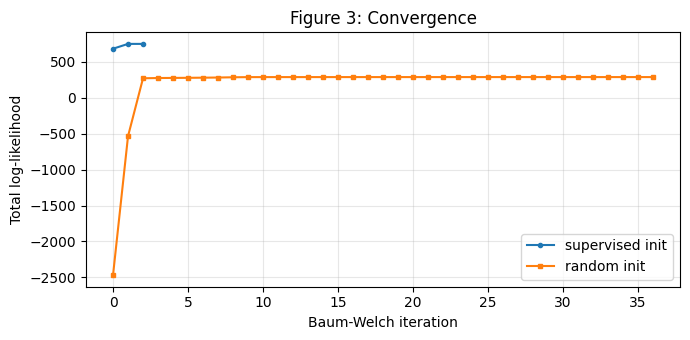

In [11]:
FLOOR = 1e-6   # keeps log(0) out of A and pi

def norm_rows(M):
    M = np.maximum(M, FLOOR)
    return M / M.sum(axis=1, keepdims=True)


def init_supervised(seqs, labels):
    X, y = np.vstack(seqs), np.concatenate(labels)
    mu  = np.array([X[y == i].mean(axis=0) for i in range(N_STATES)])
    var = np.array([X[y == i].var(axis=0) + 1e-2 for i in range(N_STATES)])

    pi = np.bincount([l[0] for l in labels], minlength=N_STATES) + 1.0
    pi /= pi.sum()

    # Every file holds one activity, so observed transitions are all self-loops.
    A = np.ones((N_STATES, N_STATES)) * 2.0
    for l in labels:
        for a, b in zip(l[:-1], l[1:]):
            A[a, b] += 1
    return pi, norm_rows(A), mu, var


def init_random(seqs):
    X = np.vstack(seqs)
    mu  = X[RNG.choice(len(X), N_STATES, replace=False)]
    var = np.tile(X.var(axis=0), (N_STATES, 1))
    pi  = np.full(N_STATES, 1 / N_STATES)
    A   = norm_rows(RNG.random((N_STATES, N_STATES)) + 1.0)
    return pi, A, mu, var


def baum_welch(seqs, pi, A, mu, var, max_iter=200, tol=1e-4):
    history = []
    for it in range(max_iter):
        g_sum  = np.zeros(N_STATES)
        g_x    = np.zeros((N_STATES, N_FEATURES))
        g_xx   = np.zeros((N_STATES, N_FEATURES))
        xi_sum = np.zeros((N_STATES, N_STATES))
        pi_sum = np.zeros(N_STATES)
        total_ll = 0.0

        logA, logpi = np.log(A), np.log(pi)

        for X in seqs:
            logB = log_gaussian(X, mu, var)
            la, ll = forward(logB, logpi, logA)
            lb     = backward(logB, logA)
            total_ll += ll

            g = np.exp(la + lb - ll)
            pi_sum += g[0]
            g_sum  += g.sum(axis=0)
            g_x    += g.T @ X
            g_xx   += g.T @ (X ** 2)

            for t in range(len(X) - 1):
                xi = la[t][:, None] + logA + logB[t+1][None, :] + lb[t+1][None, :] - ll
                xi_sum += np.exp(xi)

        pi  = np.maximum(pi_sum, FLOOR); pi /= pi.sum()
        A   = norm_rows(xi_sum)
        mu  = g_x / g_sum[:, None]
        var = np.maximum(g_xx / g_sum[:, None] - mu ** 2, 1e-2)

        history.append(total_ll)
        if it > 0 and abs(history[-1] - history[-2]) < tol:
            break
    return pi, A, mu, var, history


pi, A, mu, var, ll_sup = baum_welch(train_seqs, *init_supervised(train_seqs, train_labels))
_,  _, _,  _,   ll_rnd = baum_welch(train_seqs, *init_random(train_seqs))

print(f"supervised init: {len(ll_sup):3d} iters, final LL {ll_sup[-1]:9.2f}")
print(f"random init    : {len(ll_rnd):3d} iters, final LL {ll_rnd[-1]:9.2f}")

plt.figure(figsize=(7, 3.5))
plt.plot(ll_sup, marker="o", ms=3, label="supervised init")
plt.plot(ll_rnd, marker="s", ms=3, label="random init")
plt.xlabel("Baum-Welch iteration"); plt.ylabel("Total log-likelihood")
plt.title("Figure 3: Convergence"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

Decode and evaluate

In [12]:
# Viterbi decoding on unseen test data

logA, logpi = np.log(A), np.log(pi)

y_true, y_pred = [], []
for X, lab in zip(test_seqs, test_labels):
    path, _ = viterbi(log_gaussian(X, mu, var), logpi, logA)
    y_pred.append(path); y_true.append(lab)

y_true = np.concatenate(y_true); y_pred = np.concatenate(y_pred)

cm = np.zeros((N_STATES, N_STATES), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1

rows = []
for i, act in enumerate(ACTIVITIES):
    TP = cm[i, i]
    FN = cm[i].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = cm.sum() - TP - FN - FP
    rows.append(dict(Activity=act.capitalize(), Samples=cm[i].sum(),
                     Sensitivity=TP / (TP + FN) if TP + FN else 0,
                     Specificity=TN / (TN + FP) if TN + FP else 0,
                     Accuracy=(TP + TN) / cm.sum()))

results = pd.DataFrame(rows)
overall = (y_true == y_pred).mean()

print(results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"\nOverall accuracy: {overall:.3f}  ({(y_true==y_pred).sum()}/{len(y_true)} windows)")
print("\nConfusion matrix (rows = true, cols = predicted)")
print(pd.DataFrame(cm, index=ACTIVITIES, columns=ACTIVITIES).to_string())

Activity  Samples  Sensitivity  Specificity  Accuracy
   Still        6        1.000        1.000     1.000
Standing        6        1.000        1.000     1.000
 Walking        6        1.000        1.000     1.000
 Jumping        6        1.000        1.000     1.000

Overall accuracy: 1.000  (24/24 windows)

Confusion matrix (rows = true, cols = predicted)
          still  standing  walking  jumping
still         6         0        0        0
standing      0         6        0        0
walking       0         0        6        0
jumping       0         0        0        6


Visualisations and cross-validation

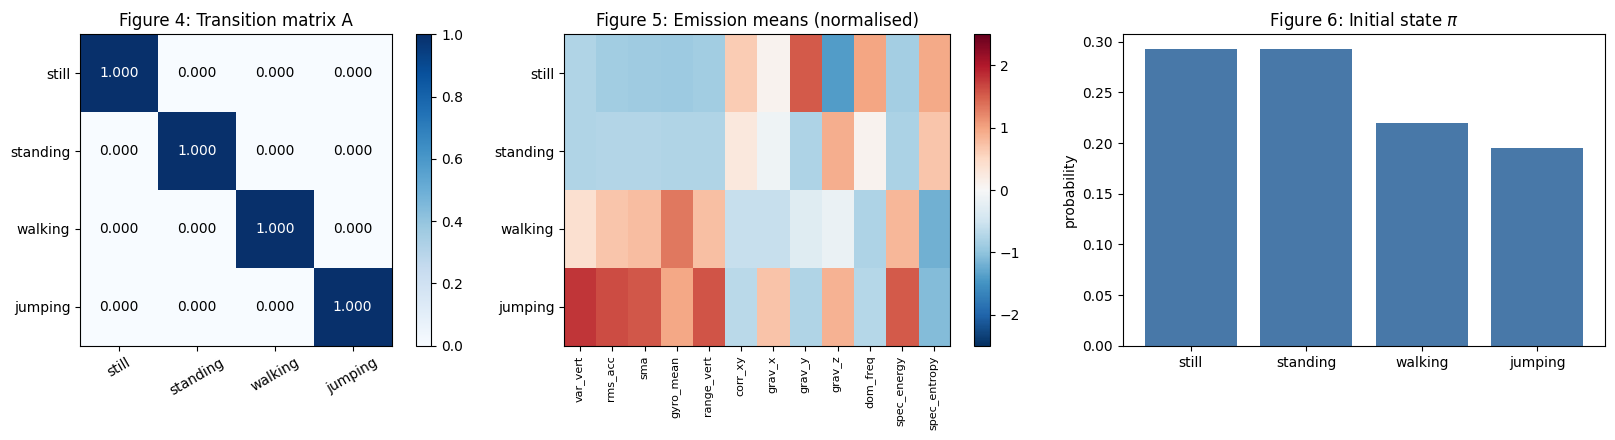

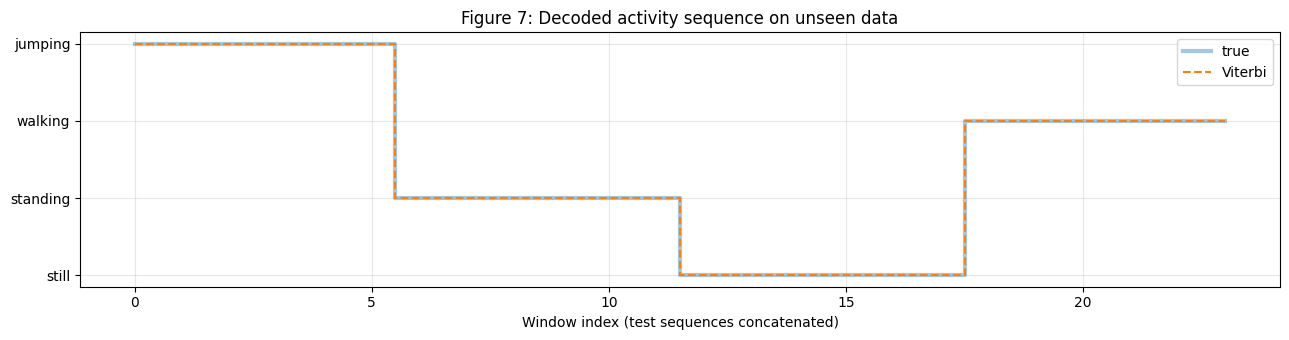

Leave-one-session-out CV over 16 sessions

Activity  Samples  Sensitivity  Specificity  Accuracy
   Still       46        1.000        1.000     1.000
Standing       48        1.000        1.000     1.000
 Walking       36        1.000        1.000     1.000
 Jumping       31        1.000        1.000     1.000

CV accuracy: 1.000  (161/161)

Confusion matrix (rows = true, cols = predicted)
          still  standing  walking  jumping
still        46         0        0        0
standing      0        48        0        0
walking       0         0       36        0
jumping       0         0        0       31


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

im = ax[0].imshow(A, cmap="Blues", vmin=0, vmax=1)
for i in range(N_STATES):
    for j in range(N_STATES):
        ax[0].text(j, i, f"{A[i,j]:.3f}", ha="center", va="center",
                   color="white" if A[i,j] > .5 else "black", fontsize=10)
ax[0].set_xticks(range(N_STATES), ACTIVITIES, rotation=30)
ax[0].set_yticks(range(N_STATES), ACTIVITIES)
ax[0].set_title("Figure 4: Transition matrix A"); plt.colorbar(im, ax=ax[0])

im = ax[1].imshow(mu, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax[1].set_xticks(range(N_FEATURES), FEATURE_NAMES, rotation=90, fontsize=8)
ax[1].set_yticks(range(N_STATES), ACTIVITIES)
ax[1].set_title("Figure 5: Emission means (normalised)"); plt.colorbar(im, ax=ax[1])

ax[2].bar(ACTIVITIES, pi, color="#4878a8")
ax[2].set_ylabel("probability"); ax[2].set_title("Figure 6: Initial state $\\pi$")
plt.tight_layout(); plt.show()


# Figure 7: decoded vs true, test sequences concatenated
plt.figure(figsize=(13, 3.5))
plt.step(range(len(y_true)), y_true, where="mid", lw=3, alpha=.4, label="true")
plt.step(range(len(y_pred)), y_pred, where="mid", lw=1.5, ls="--", label="Viterbi")
plt.yticks(range(N_STATES), ACTIVITIES)
plt.xlabel("Window index (test sequences concatenated)")
plt.title("Figure 7: Decoded activity sequence on unseen data")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()


# Leave-one-session-out CV: harder test, many more windows
sessions_of = ["_".join(n.split("_")[:2]) for n in train_names]   # e.g. walking_s2
uniq = sorted(set(sessions_of))

cm_cv = np.zeros((N_STATES, N_STATES), dtype=int)
for held in uniq:
    tr = [i for i, s in enumerate(sessions_of) if s != held]
    te = [i for i, s in enumerate(sessions_of) if s == held]

    p_, A_, m_, v_, _ = baum_welch([train_seqs[i] for i in tr],
                                   *init_supervised([train_seqs[i] for i in tr],
                                                    [train_labels[i] for i in tr]))
    lA_, lp_ = np.log(A_), np.log(p_)
    for i in te:
        path, _ = viterbi(log_gaussian(train_seqs[i], m_, v_), lp_, lA_)
        for t, p in zip(train_labels[i], path):
            cm_cv[t, p] += 1

rows = []
for i, act in enumerate(ACTIVITIES):
    TP = cm_cv[i, i]; FN = cm_cv[i].sum() - TP
    FP = cm_cv[:, i].sum() - TP; TN = cm_cv.sum() - TP - FN - FP
    rows.append(dict(Activity=act.capitalize(), Samples=cm_cv[i].sum(),
                     Sensitivity=TP/(TP+FN) if TP+FN else 0,
                     Specificity=TN/(TN+FP) if TN+FP else 0,
                     Accuracy=(TP+TN)/cm_cv.sum()))

print(f"Leave-one-session-out CV over {len(uniq)} sessions\n")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"\nCV accuracy: {np.trace(cm_cv)/cm_cv.sum():.3f}  ({np.trace(cm_cv)}/{cm_cv.sum()})")
print("\nConfusion matrix (rows = true, cols = predicted)")
print(pd.DataFrame(cm_cv, index=ACTIVITIES, columns=ACTIVITIES).to_string())

Realistic transitions and composite decoding

Transition matrix from expected durations
          still  standing  walking  jumping
still    0.9355    0.0215   0.0215   0.0215
standing 0.0317    0.9048   0.0317   0.0317
walking  0.0416    0.0416   0.8752   0.0416
jumping  0.0737    0.0737   0.0737   0.7788


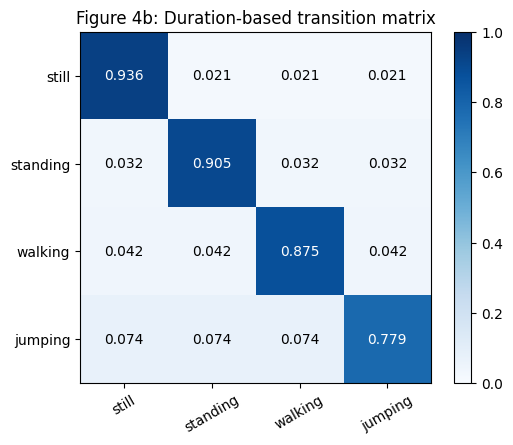

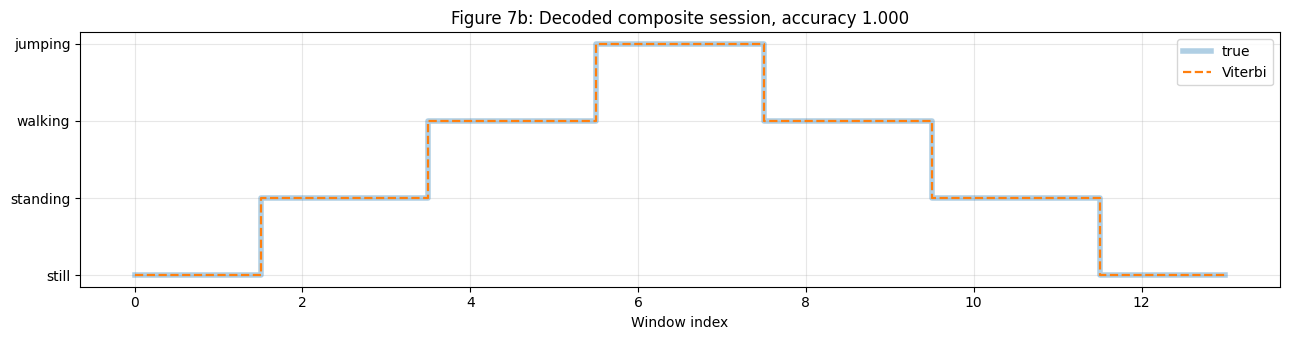

Composite sequence: 14 windows, accuracy 1.000


In [14]:
# real behaviour, so A is set from expected activity durations instead

HOLD_S = {"still": 30.0, "standing": 20.0, "walking": 15.0, "jumping": 8.0}
step_s = WINDOW_STEP / FS_NOMINAL

A_real = np.zeros((N_STATES, N_STATES))
for i, act in enumerate(ACTIVITIES):
    stay = np.exp(-step_s / HOLD_S[act])          # survival over one window step
    A_real[i] = (1 - stay) / (N_STATES - 1)
    A_real[i, i] = stay

print("Transition matrix from expected durations")
print(pd.DataFrame(A_real, index=ACTIVITIES, columns=ACTIVITIES).to_string(
      float_format=lambda v: f"{v:.4f}"))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(A_real, cmap="Blues", vmin=0, vmax=1)
for i in range(N_STATES):
    for j in range(N_STATES):
        ax.text(j, i, f"{A_real[i,j]:.3f}", ha="center", va="center",
                color="white" if A_real[i,j] > .5 else "black", fontsize=10)
ax.set_xticks(range(N_STATES), ACTIVITIES, rotation=30)
ax.set_yticks(range(N_STATES), ACTIVITIES)
ax.set_title("Figure 4b: Duration-based transition matrix")
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()


# Composite sequence: what a real monitoring session looks like
script = ["still", "standing", "walking", "jumping", "walking", "standing", "still"]
pool = {a: [X for X, l in zip(test_seqs, test_labels) if l[0] == ACTIVITIES.index(a)]
        for a in ACTIVITIES}

comp_X, comp_y = [], []
for k, act in enumerate(script):
    X = pool[act][k % len(pool[act])]
    comp_X.append(X); comp_y.append(np.full(len(X), ACTIVITIES.index(act)))
comp_X = np.vstack(comp_X); comp_y = np.concatenate(comp_y)

path, _ = viterbi(log_gaussian(comp_X, mu, var), np.log(pi), np.log(A_real))
acc = (path == comp_y).mean()

plt.figure(figsize=(13, 3.5))
plt.step(range(len(comp_y)), comp_y, where="mid", lw=4, alpha=.35, label="true")
plt.step(range(len(path)), path, where="mid", lw=1.6, ls="--", label="Viterbi")
plt.yticks(range(N_STATES), ACTIVITIES)
plt.xlabel("Window index"); plt.title(
    f"Figure 7b: Decoded composite session, accuracy {acc:.3f}")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print(f"Composite sequence: {len(comp_y)} windows, accuracy {acc:.3f}")